L=10.0 [mm], d=1.0 [mm], order=3, phi0=0.9, lambda_target=8.0
Computed mu_bar = 0.006114063687894593 for lambda_target = 8.0
Entropic unit = 137.21 [MPa], G = 0.1372 [MPa], chi = 0.4, p0_bar = 0.0000233, lambda_target = 8.0
gel.Gfun(lambda_target) = 0.13721100772787642
filename_suffix=_phi0=0.9_absMuBar=0.006
sum(fes.FreeDofs()) = 68070
Iteration=160
Average energy density =  -74.32645
'Macroscopic' vertical stretch:  8.000927885350038
uniaxial_sigma_11=-1.08055631079375
Average compressive stress =  -1.08055


WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.2…

 
Iteration=161
Average energy density =  -74.32645
'Macroscopic' vertical stretch:  8.000903594028356
uniaxial_sigma_11=-1.08055631079375
Average compressive stress =  -1.08055


WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.2…

 
Iteration=162
Average energy density =  -74.32645
'Macroscopic' vertical stretch:  8.000880517367746
uniaxial_sigma_11=-1.08055631079375
Average compressive stress =  -1.08055


WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.2…

... (2 outputs left out)

 
Iteration=164
Average energy density =  -74.32645
'Macroscopic' vertical stretch:  8.000837768097206
uniaxial_sigma_11=-1.08055631079375
Average compressive stress =  -1.08055


WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.2…

 
Iteration=165
Average energy density =  -74.32645
'Macroscopic' vertical stretch:  8.000817982964323
uniaxial_sigma_11=-1.08055631079375
Average compressive stress =  -1.08055


WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.2…

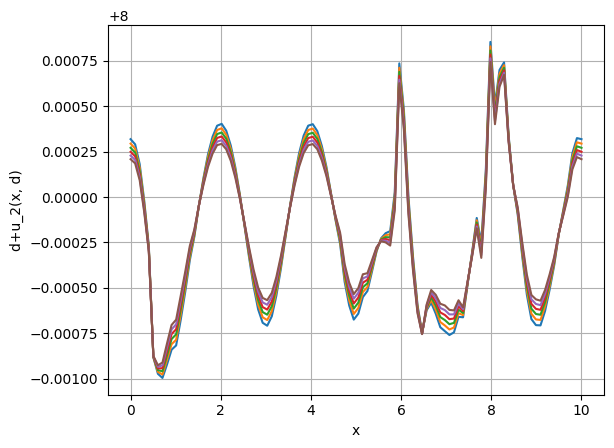

In [59]:
from ngsolve import *
from ngsolve.webgui import Draw
from ClassGels3 import gel2d
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# READ PARAMETERS
# It will be assumed that the arguments passed from shell
# are, in that order:
# the length; the thickness; the order for the finite element space;
# the initial polymer volume fraction phi0; 
# the target theoretical uniaxial stretch lambda_h 
# For example,
#    100 20 3 0.9 2.0
# means L=100, d=20, order=3, phi0=0.9, lambda_h=2.0
# ---------------------------------------------------------
# data = sys.argv
day = '20261122'
lamb,time = [8.0,'0827']  # amp_rel = 100%
# lamb,time = [7.0,'0816']  # amp_rel = 100%
# lamb,time = [7.0,'0813']  # amp_rel = 50%
# lamb,time = [7.0,'0808']  # amp_rel = 10%
# lamb,time = [7.0,'0805']  # amp_rel = 3%
# lamb,time = [7.0,'0801']  # amp_rel =2%
# lamb,time = [7.0,'0759']  # amp_rel =1%
# lamb,time = [6.0,'0756']
# lamb,time = [5.0,'0755']
# lamb,time = [4.0,'0752']
# lamb,time = [3.0,'0746']
data = ['dummy', '10', '1', '3', '0.9', str(lamb)]
# data = ['dummy', '10', '1', '3', '0.9', '2.1']
# data = ['dummy', '10', '1', '3', '0.9', '2.0']
# data = ['dummy', '100', '20', '3', '0.9', '2.0']
L = float(data[1])
d = float(data[2])
order = int(data[3])
phi0 = float(data[4])
# mu_input = float(data[5])    
# mu_bar = -mu_input  # internal sign convention
# print(f'L={L} [mm], d={d} [mm], order={order}, phi0={phi0}, mu_bar={mu_bar}')
lambda_target = float(data[5])
print(f'L={L} [mm], d={d} [mm], order={order}, phi0={phi0}, lambda_target={lambda_target}')
# gel = gel2d(L,d,phi0,mu_bar)
gel = gel2d(L,d,phi0,lambda_target)
# ---------------------------------------------------------
# LOAD MESH
# ---------------------------------------------------------
# mesh_file = 'meshes/mesh.vol'
mesh_file = 'meshes/meshPeriodic.vol'
mesh = Mesh(mesh_file)
# ---------------------------------------------------------
# FINITE ELEMENT SPACE
# Finite element space with zero-displacement boundary condition on the whole interface
# and periodic boundary conditions identifying left and right.
# ---------------------------------------------------------
fes = Periodic(VectorH1(mesh, order=order, \
                    dirichlet="bot"))
print(f'sum(fes.FreeDofs()) = {sum(fes.FreeDofs())}')
# ---------------------------------------------------------
# LOAD SIMULATION
# ---------------------------------------------------------
simulation_name = 'test' + day + time
gfu = GridFunction(fes) 
# maxits = 100
# indexes_iterations = [0]
# indexes_iterations = [50, 100,150, 200]
# indexes_iterations = [200]
# indexes_iterations = range(0,1+1)
# indexes_iterations = range(0,3+1)
# indexes_iterations = range(0,5+1)
# indexes_iterations = range(0,10+1)
# indexes_iterations = range(11,20+1)
# indexes_iterations = range(21,30+1)
# indexes_iterations = range(31,40+1)
# indexes_iterations = range(41,50+1)
# indexes_iterations = range(91,100+1)
# indexes_iterations = range(100,103+1)
indexes_iterations = range(160,165+1)
# indexes_iterations = range(190,192+1)
# indexes_iterations = range(190,194+1)
# indexes_iterations = range(310,321+1)
for it in indexes_iterations:
    filename_main = gel.filename_main(simulation_name)
    filename = filename_main + '_Newton=' + str(it).zfill(2)
    #
    gfu.Load(filename + '.gfu')
    F = Id(2) + Grad(gfu)
    # Draw(gel.W(F), mesh, deformation=u)
    # Draw(gel.W(F), mesh)
    print(f'Iteration={it}')
    print('Average energy density = ', round(Integrate(gel.W(F), mesh)/(L*d),5))   
    vertex_values = [(y+gfu[1])(mesh(*p)) for p in mesh.ngmesh.Points()]
    print(f'\'Macroscopic\' vertical stretch: ', max(vertex_values)/gel.d) 
    uniaxial_compressive_stress = -gel.entropic_unit*gel.gamma*(lambda_target-1/lambda_target) 
    print(f'uniaxial_sigma_{11}={uniaxial_compressive_stress}')
    # gel.mu_bar.Set(previous_mu_bar)
    print('Average compressive stress = ', round(Integrate(gel.sigma_xx(F), mesh)/(L*d),5))  
    #
    X = np.linspace(0.0, L, 100)
    eps = 1e-9
    Y = np.full_like(X, d-eps)
    # Evaluate gfu[1] along (x, d)
    vals = Y+np.asarray(gfu[1](mesh(X, Y))).ravel()
    plt.plot(X, vals)
    plt.xlabel("x")
    plt.ylabel("d+u_2(x, d)")
    # plt.ylim([1.9, 2.1])
    plt.grid(True)
    # plt.show()
    #
    Draw(-gel.sigma_xx(F), mesh, deformation=gfu)
    # Draw(y+gfu[1], mesh, deformation=gfu)
    print(' ')

In [3]:
from ngsolve import *
from ngsolve.webgui import Draw
mesh_file = 'meshes/meshPeriodic.vol'
mesh = Mesh(mesh_file)
Draw(x,mesh)

WebGuiWidget(layout=Layout(height='500px', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.2…

BaseWebGuiScene